<a href="https://colab.research.google.com/github/maudem-data/DATA-101/blob/main/sample_projects/DS_CS_activity.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Introduction to Data Science


<p>Data science is a dynamic field that has emerged in the digital age, characterized by the abundance of data available. It is an interdisciplinary domain that combines statistics, computer science, and domain-specific knowledge to extract insights from data. </p>
<ul>
<li><p><strong>Definition and Scope</strong>: Data science involves collecting, organizing, analyzing, and interpreting data to derive meaningful insights. It is applicable across various fields such as healthcare, finance, and social sciences.</p>
</li>
<li><p><strong>Data Analysis Methods</strong>: It employs a range of methods, from descriptive statistics to advanced modeling techniques like decision trees and k-means clustering. These methods help in understanding data patterns and making predictions.</p>
</li>
<li><p><strong>Data Storytelling</strong>: A crucial aspect of data science is data storytelling, which involves creating compelling narratives through visualizations and reports to communicate findings effectively.</p>
</li>
<li><p><strong>Lifecycle and Impact</strong>: The data science lifecycle includes data collection, preparation, analysis, and insight generation. Its impact is profound, driving decision-making and innovation in numerous industries.</p>
</li>
</ul>
<p>Data science is essential for navigating our data-rich world, offering tools and techniques to make data-driven decisions. </p>

## Data Science Lifecycle

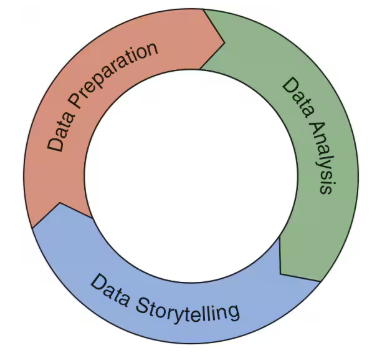

## Case study: Netflix uses data science to enhance its customer experience

- Personalized Recommendations: Netflix collects data on viewing habits, such as when and how often subscribers watch shows, to create personalized content recommendations for each user.

- Data Visualization: The company uses visualization tools to convert raw data into dashboards with graphs and charts. This helps analysts explore data and develop new features for the service.

- A/B Testing: Netflix conducts A/B tests to experiment with different subscription offers. By sending different offers to randomly selected customers, they can determine which is more effective and why.

- Traffic and Operations Analysis: Data science is used to analyze Netflix's traffic and operations, ensuring efficient service delivery and maintaining information security.

These practices have helped Netflix grow significantly, making it a leading streaming platform by leveraging data analysis, machine learning, and statistics.

# Data Science Lifecycle: An Introduction with the Iris Dataset

Welcome to this hands-on activity!
In this notebook, you will walk through the core steps of the data science lifecycle:
1. Data Gathering
2. Data Cleaning/Selection
3. Data Visualization
4. Simple Classification using k-Nearest Neighbors (if time permits)

We'll be working with the classic Iris flower dataset.

Let's get started!

## Data Gathering

In [ ]:
# Step 1: Data Gathering
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris

# Load the Iris dataset from sklearn
iris = load_iris()

# Convert to a Pandas DataFrame
data = pd.DataFrame(iris.data, columns=iris.feature_names)

data['species'] = pd.Categorical.from_codes(iris.target, iris.target_names)

# Show the first few rows of the dataset
print("First five rows of the dataset:")
data.head()

First five rows of the dataset:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


## Data Cleaning/Selection

In [ ]:
# Step 2: Data Cleaning/Selection
# Let's inspect for any missing or duplicate data
print("\nChecking for missing values:")
print(data.isnull().sum())

print("\nChecking for duplicates:")
print(f"Number of duplicate rows: {data.duplicated().sum()}")


Checking for missing values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64

Checking for duplicates:
Number of duplicate rows: 1


In [ ]:
# Remove any duplicates (if any)
data = data.drop_duplicates()

In [ ]:
# For simplicity, we'll focus on two features for visualization: petal length and petal width
# --- Experiment: Try different combinations of features like 'sepal length (cm)', 'sepal width (cm)' ---
selected_features = ['petal length (cm)', 'petal width (cm)', 'species']
data_selected = data[selected_features]

## Data Visualization


Visualizing the data:


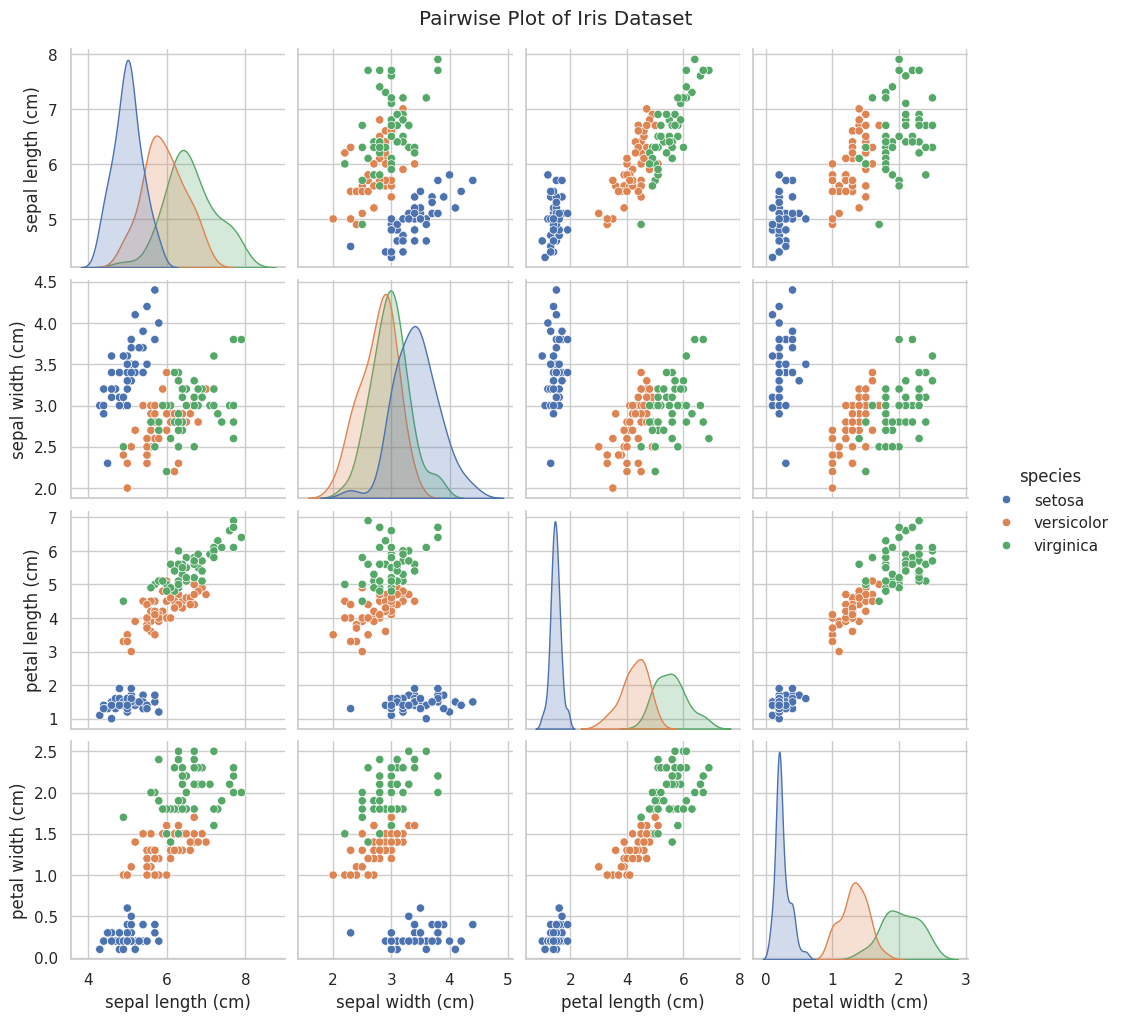

In [ ]:
# Step 3: Data Visualization
# Let's create some plots to explore the data visually
print("\nVisualizing the data:")
sns.set(style="whitegrid")

# --- Experiment: Try changing diag_kind to 'hist' or altering hue to another feature ---
sns.pairplot(data, hue="species", diag_kind="kde")
plt.suptitle("Pairwise Plot of Iris Dataset", y=1.02)
plt.show()

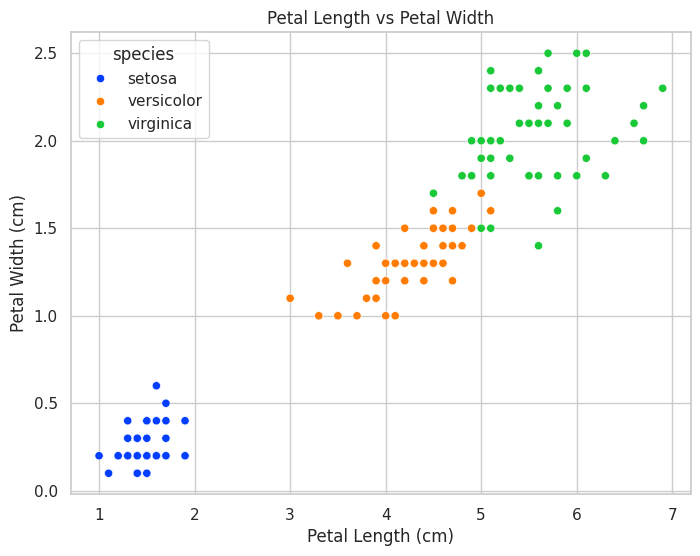

In [ ]:
# Scatter plot of selected features
# --- Experiment: Change the palette to 'dark', 'pastel', or try a custom color palette ---
plt.figure(figsize=(8, 6))
sns.scatterplot(
    x='petal length (cm)',
    y='petal width (cm)',
    hue='species',
    data=data_selected,
    palette='bright')
plt.title("Petal Length vs Petal Width")
plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")
plt.show()

## Simple Classification using k-Nearest Neighbors

### 🤖 Understanding the k-Nearest Neighbors (kNN) Algorithm

#### 📌 What is kNN?

**k-Nearest Neighbors** (kNN) is a **simple machine learning algorithm** used for **classification** (and sometimes regression). It predicts the label of a data point by **looking at the labels of the “k” closest data points** in the training set.

Think of it as **“asking your neighbors”** for advice!

---

### 🧠 How Does It Work?

Let’s say you want to predict the species of a new flower based on its measurements:

1. **Measure the distance** from this flower to all other flowers in the training set (usually using Euclidean distance).
2. **Pick the “k” closest neighbors** (e.g., the 3 nearest flowers).
3. **Check their species**.
4. The most common species among those neighbors becomes the prediction!

---

### 🧮 What Does “k” Mean?

* `k` is the number of neighbors the algorithm uses to make a decision.
* A small `k` (like 1) means the prediction is very sensitive to noise.
* A larger `k` is more stable but might blur the boundaries between classes.

Try values like `k = 1, 3, 5, 10` and observe how the accuracy changes!

---

### 📦 Summary

| Step | What Happens                           |
| ---- | -------------------------------------- |
| 1️⃣  | Find the distances to all other points |
| 2️⃣  | Pick the k closest ones                |
| 3️⃣  | Count how many of each class           |
| 4️⃣  | Predict the most common class          |

---

### 🧠 Why It’s Great for Beginners

* No training phase — the model “learns” by comparing!
* Easy to understand and implement.
* Works well for small datasets like the Iris dataset.

---

### 📉 Limitations

* Slow on large datasets (must compare to every point).
* Doesn't work well if the features have different scales (feature scaling helps).
* Sensitive to irrelevant or noisy features.



In [ ]:
# Optional Extension (If Time Permits):
# Simple Classification using k-Nearest Neighbors
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# Prepare features and labels
X = data_selected.drop(columns='species')
y = data_selected['species']

# Split into train and test sets
# --- Experiment: Change test_size to 0.3 or 0.1 and see how it affects accuracy ---
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Train a simple k-NN model
# --- Experiment: Try different values for n_neighbors like 1, 5, or 10 ---
knn = KNeighborsClassifier(n_neighbors=6)
knn.fit(X_train, y_train)

# Predict and evaluate
predictions = knn.predict(X_test)
accuracy = accuracy_score(y_test, predictions)
print(f"\nClassification Accuracy (k-NN): {accuracy * 100:.2f}%")

# --- Experiment: Print predictions vs. actual values for deeper insight ---
print("\nSample predictions:")
comparison_df = pd.DataFrame({'Actual': y_test, 'Predicted': predictions})
print(comparison_df.head())

# End of Activity
print("\nGreat job! You've completed a basic walkthrough of the data science lifecycle.")



Classification Accuracy (k-NN): 100.00%

Sample predictions:
         Actual   Predicted
73   versicolor  versicolor
18       setosa      setosa
117   virginica   virginica
78   versicolor  versicolor
76   versicolor  versicolor

Great job! You've completed a basic walkthrough of the data science lifecycle.


# Reflection and Discussion Points:
1. What happens to the accuracy when you change the value of `n_neighbors`? Why might this be?
2. How does the model performance change when you include different features or all four features?
3. Are there certain species that are more difficult to classify correctly? How might you improve the model?
4. What are some potential limitations of using k-NN for classification?
5. Can you think of a real-world application where a model like this would be useful?